# Diffusion encoding

`gropt.diffusion` builds spin-echo diffusion problems from a `DiffParams` (timing, hardware limits and
constraints), and `solve` maximizes the b-value at that TE. The solver settings default to a recipe tuned
over a wide range of diffusion problems, so most problems need only a `DiffParams`.

In [1]:
from dataclasses import replace

import numpy as np

from gropt.diffusion import DiffParams, solve, to_raster, verify
from gropt.plot import get_bval, plot_diff

b = 445 s/mm^2, converged = True, 3.1 ms


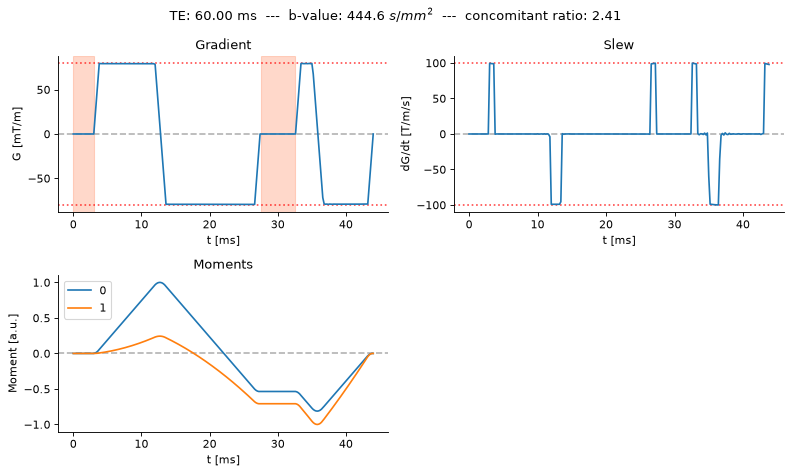

In [2]:
cfg = DiffParams(
    TE=60e-3,          # echo time [s]
    T_90=3e-3,         # excitation time after t = 0 (half the pulse) [s]
    T_180=5e-3,        # refocusing pulse duration [s]
    T_readout=16e-3,   # readout time before TE [s]
    dt=200e-6,         # solve raster [s]
    gmax=0.08,         # [T/m]
    smax=100.0,        # [T/m/s]
    MMT=1,             # null M0 and M1
)
res = solve(cfg)
print(f"b = {res['bvalue']:.0f} s/mm^2, converged = {res['converged']}, {1e3 * res['solve_time']:.1f} ms")
plot_diff(cfg, res)

The RF pulses are shaded; the waveform is held at 0 there. The moment panel shows the running
moments (with the sign flip at the 180), each scaled to a peak of 1.

The result is a plain dict: `X` (the waveform), `bvalue`, `converged`, `n_iter`, `solve_time`,
`inv_vec`, and a `warmstart` snapshot for a follow-up solve.

## Checking a waveform

`converged` means the solver's own checks passed on the solve raster. `verify` re-checks every limit from
the waveform alone (PNS on the 10 µs hardware raster, concomitant balance with the exact integral) and
returns the worst value-to-limit ratio of each, 1.0 being at the limit.

In [3]:
verify(res, cfg)

{'g_ratio': np.float64(0.9933941313842998),
 's_ratio': np.float64(0.999311670865223),
 'pns_ratio': nan,
 'cns_ratio': nan,
 'concomitant_ratio': nan,
 'max_ratio': 0.999311670865223,
 'feasible': True}

## Moment nulling

Each nulled moment costs b-value at a fixed TE:

In [4]:
for MMT in range(4):
    r = solve(replace(cfg, MMT=MMT))
    print(f"MMT={MMT}: b = {r['bvalue']:6.0f} s/mm^2")

MMT=0: b =   1799 s/mm^2
MMT=1: b =    445 s/mm^2
MMT=2: b =    177 s/mm^2
MMT=3: b =    136 s/mm^2


## Compared with a conventional waveform

`diff_mode="conventional"` adds dead time before the 180 so that the lobes on either side have the same
duration, the usual symmetric design. The GrOpt layout uses the whole time on both sides instead.

conventional: b = 87 s/mm^2   GrOpt: b = 445 s/mm^2


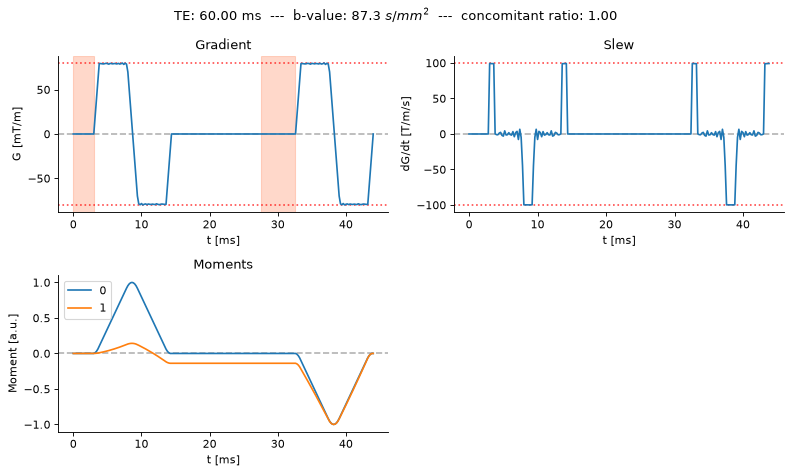

In [5]:
conv = replace(cfg, diff_mode='conventional')
res_conv = solve(conv)
print(f"conventional: b = {res_conv['bvalue']:.0f} s/mm^2   GrOpt: b = {res['bvalue']:.0f} s/mm^2")
plot_diff(conv, res_conv)

## Concomitant fields and eddy currents

- `concomitant=True` balances the gradient energy before and after the 180, so that the concomitant-field
  phase refocuses; exactly by default, or within `concomitant_tol` with `concomitant_project=False`.
- `eddy_lam` nulls the eddy current residual at the end of the waveform for a time constant (or several)
  in seconds. The eddy panel shows the residual over a range of time constants.

concomitant  b =   246 s/mm^2  feasible: True
eddy 10 ms   b =   200 s/mm^2  feasible: True
both         b =   127 s/mm^2  feasible: True


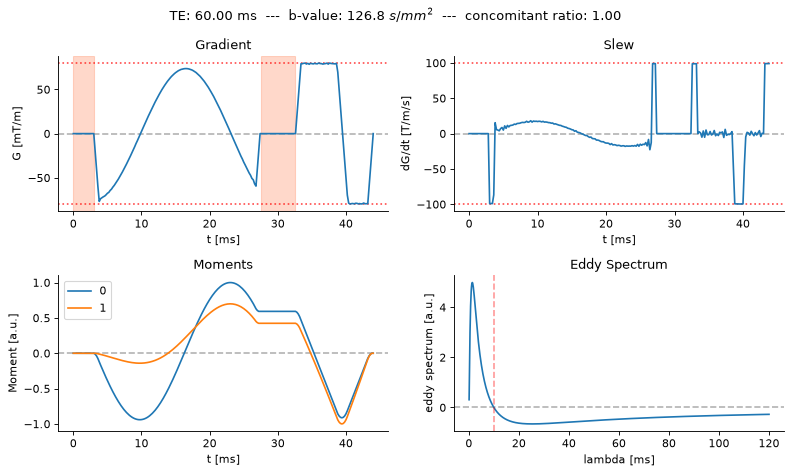

In [6]:
for name, c in (('concomitant', replace(cfg, concomitant=True)),
                ('eddy 10 ms', replace(cfg, eddy_lam=10e-3)),
                ('both', replace(cfg, concomitant=True, eddy_lam=10e-3))):
    r = solve(c)
    print(f"{name:12s} b = {r['bvalue']:5.0f} s/mm^2  feasible: {verify(r, c)['feasible']}")
plot_diff(c, r)

## Stronger gradients, PNS and cardiac stimulation

`pns_lim` and `cns_lim` limit the SAFE-model PNS and cardiac stimulation, as fractions of their
thresholds. The model parameters default to a random but realistic set (`safe_params=None`); use
`safe_params=SafeSource(kind="asc", asc_file=...)` for a scanner's, or a `(pns, cns)` pair of dicts.
`safe_test_axes` chooses which axes' coefficients to stay safe on (default x only).

200 mT/m, 200 T/m/s  b =  2695 s/mm^2    2.4 ms


+ PNS, CNS <= 0.8    b =  1454 s/mm^2   94.1 ms


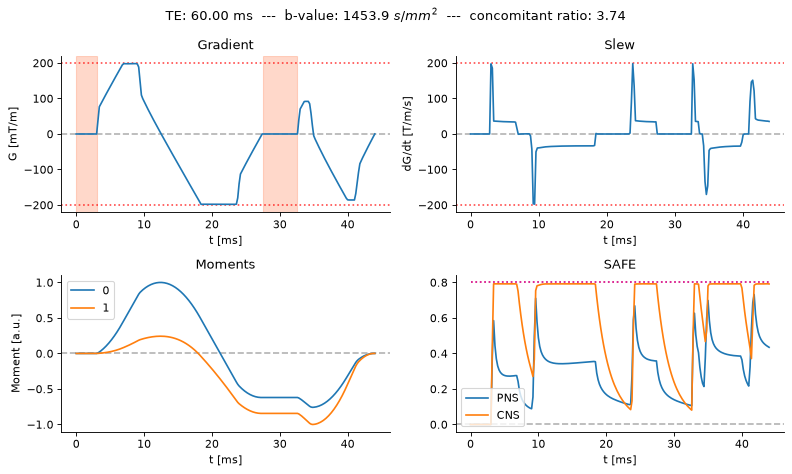

In [7]:
hw = replace(cfg, gmax=0.2, smax=200.0)
hw_safe = replace(hw, pns_lim=0.8, cns_lim=0.8)
for name, c in (('200 mT/m, 200 T/m/s', hw), ('+ PNS, CNS <= 0.8', hw_safe)):
    r = solve(c)
    print(f"{name:20s} b = {r['bvalue']:5.0f} s/mm^2  {1e3 * r['solve_time']:5.1f} ms")
plot_diff(hw_safe, r)

## Solve raster and hardware raster

The scanner plays gradients on a fine raster (10 µs), but the solve can use a much coarser one:
`to_raster` resamples a solution exactly (the scanner interpolates linearly, so gradient, slew and moments
are unchanged). What a coarse raster costs is the RF gaps, which are rounded outward to the solve grid.

In [8]:
for dt in (400e-6, 200e-6, 100e-6, 10e-6):
    c = replace(cfg, dt=dt)
    r = solve(c)
    hw_res = to_raster(r, 10e-6)
    b10 = get_bval(hw_res['X'], 10e-6, hw_res['inv_vec'])
    print(f"dt = {dt * 1e6:3.0f} us: b on the 10 us raster = {b10:5.0f} s/mm^2, solve {1e3 * r['solve_time']:6.1f} ms")

dt = 400 us: b on the 10 us raster =   425 s/mm^2, solve    1.4 ms
dt = 200 us: b on the 10 us raster =   444 s/mm^2, solve    3.0 ms
dt = 100 us: b on the 10 us raster =   450 s/mm^2, solve    3.8 ms


dt =  10 us: b on the 10 us raster =   450 s/mm^2, solve   96.5 ms


A 100 or 200 µs solve gets within about 1% of the 10 µs b-value in a few percent of the time. (The solver's
own `res['bvalue']` uses a rectangle rule that reads slightly high on a coarse raster; `bval_pwl_quad=True`
makes it exact, which `te_search` does.) Recipes, TE searches and sweeps are in
[Minimum TE, recipes and sweeps](diffusion_te.ipynb).